# Chapter 2: What will mistakes cost us: what does wrong cost?

*The error bill in rupees under the chosen threshold*

**Who needs the answer.** Finance, who signs the calling budget and asks what being wrong will cost before agreeing to any threshold.

**The questions on the way.** What does each kind of mistake cost? Why does the 0.5 default look cheap? Where is the bill smallest, and why does that cut sit far below 0.5?

**What you will be able to do.** Compute the error bill at any threshold, find the cheapest one by a sweep, and reach the same cut from the cost formula.

**Search terms.** cost-benefit analysis of a model, expected cost, cost-sensitive threshold

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10.5, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED, LILAC = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#CFC9EE"

def check(label, ok):
    """Print PASS or FAIL on its own line; a failed check never stops the notebook."""
    print(("PASS  " if ok else "FAIL  ") + label)

# Invented for teaching: 20 lapsed members of a gym in Indore and who came back after a call.
# Model A uses two columns (months since the last visit, visits in the last month); model B uses forty.
import numpy as np, pandas as pd
gym = pd.DataFrame({
    "member":  ["M07", "M12", "M03", "M15", "M01", "M19", "M09", "M05", "M18", "M11",
                "M02", "M14", "M06", "M20", "M08", "M16", "M04", "M13", "M10", "M17"],
    "plan":    ["student", "regular", "regular", "family", "student", "regular", "family", "regular", "student", "family",
                "regular", "regular", "family", "student", "regular", "family", "regular", "student", "regular", "family"],
    "score_A": [0.81, 0.74, 0.66, 0.58, 0.47, 0.41, 0.35, 0.29, 0.24, 0.20,
                0.17, 0.14, 0.11, 0.09, 0.07, 0.05, 0.04, 0.03, 0.02, 0.01],
    "score_B": [0.77, 0.52, 0.70, 0.61, 0.44, 0.40, 0.38, 0.33, 0.21, 0.19,
                0.25, 0.12, 0.10, 0.08, 0.15, 0.03, 0.18, 0.02, 0.04, 0.01],
    "came_back": [1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0],
})
CALL, MISS = 30, 900   # Rs per comeback call; Rs of margin lost per member who would have returned uncalled
print(f"{len(gym)} members (invented), {gym.came_back.sum()} came back; a call costs Rs {CALL}, a missed comeback Rs {MISS}")

20 members (invented), 5 came back; a call costs Rs 30, a missed comeback Rs 900


## Why does the default threshold look cheap?

Two mistakes cost money. A wasted call (called, did not return) costs Rs 30. A missed returner (not called, would have returned) costs Rs 900. A returner who is called costs Rs 30 too, but that call buys the Rs 900 back, so the bill counts the two mistakes only.

**Predict before you run.** At the default cut of 0.5, model A calls 4 members. Which bill is smaller, 0.5 or calling everyone? a) 0.5, since it makes 16 fewer calls; b) calling everyone; c) they are equal; d) it cannot be known without AUC.

In [2]:
def bill(t, col="score_A"):
    called = gym[col] >= t
    wasted = int((called & (gym.came_back == 0)).sum()); missed = int((~called & (gym.came_back == 1)).sum())
    return {"threshold": t, "calls": int(called.sum()), "wasted Rs": CALL * wasted, "missed Rs": MISS * missed, "bill Rs": CALL * wasted + MISS * missed}
pd.DataFrame([bill(0.5), bill(0.032), bill(0.0), bill(1.01)], index=["default 0.5", "cost cut 0.032", "call everyone", "call nobody"])

,threshold,calls,wasted Rs,missed Rs,bill Rs
default 0.5,0.500,4,30,1800,1830
cost cut 0.032,0.032,17,360,0,360
call everyone,0.000,20,450,0,450
call nobody,1.010,0,0,4500,4500


**What happened.** The answer is b. At 0.5 the gym spends only Rs 30 on wasted calls and loses Rs 1,800 on two returners it never called: a bill of Rs 1,830, four times the Rs 450 of calling everyone. A threshold that rarely acts always looks cheap on the call count and expensive on the bill.

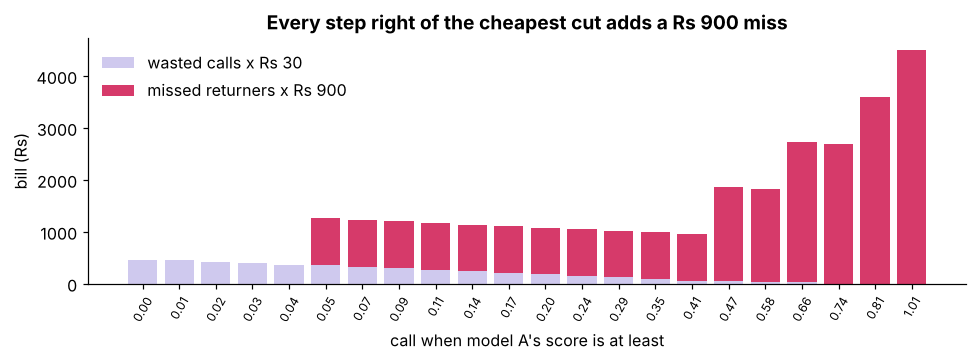

cheapest cut in the sweep: call at 0.04 or above, bill Rs 360


In [3]:
cuts = sorted(set(gym.score_A) | {0.0, 1.01})
sweep = pd.DataFrame([bill(t) for t in cuts])
fig, ax = plt.subplots(figsize=(9, 3.4))
xs = np.arange(len(sweep))
ax.bar(xs, sweep["wasted Rs"], color=LILAC, label="wasted calls x Rs 30")
ax.bar(xs, sweep["missed Rs"], bottom=sweep["wasted Rs"], color=ROSE, label="missed returners x Rs 900")
ax.set_xticks(xs); ax.set_xticklabels([f"{t:.2f}" for t in sweep.threshold], rotation=60, fontsize=8)
ax.set_xlabel("call when model A's score is at least"); ax.set_ylabel("bill (Rs)"); ax.legend(frameon=False)
ax.set_title("Every step right of the cheapest cut adds a Rs 900 miss")
plt.tight_layout(); plt.show()
cheapest = sweep.loc[sweep["bill Rs"].idxmin()]
print(f"cheapest cut in the sweep: call at {cheapest.threshold:.2f} or above, bill Rs {cheapest['bill Rs']:.0f}")

## Where does the formula put the cut?

Named last, as shorthand for the sweep. A member with chance p of returning costs `p x 900` if left uncalled and `(1 - p) x 30` if called. Calling is cheaper when `p x 900 > (1 - p) x 30`, which is `p > 30 / (30 + 900) = 0.032`. The rule with its flip: the cut is `cost of a wasted call / (wasted + missed)` while the scores are honest probabilities; it fails when the scores are not, and it stops binding when a budget caps the calls.

In [4]:
T = CALL / (CALL + MISS)
per_member = np.where(gym.score_A * MISS > (1 - gym.score_A) * CALL, "call", "skip")
print(f"formula cut: {T:.3f}; members the per-member rule calls: {(per_member == 'call').sum()}")
check("the formula cut and the per-member rule call the same members", ((gym.score_A >= T) == (per_member == "call")).all())
check("the cheapest swept bill is no larger than the formula cut's bill", cheapest["bill Rs"] <= bill(T)["bill Rs"])
check("every bill is wasted plus missed", (sweep["bill Rs"] == sweep["wasted Rs"] + sweep["missed Rs"]).all())

formula cut: 0.032; members the per-member rule calls: 17
PASS  the formula cut and the per-member rule call the same members
PASS  the cheapest swept bill is no larger than the formula cut's bill
PASS  every bill is wasted plus missed


## What did this chapter establish?

| Question | Answer |
|---|---|
| What goes in the bill? | Wasted calls x Rs 30 plus missed returners x Rs 900; returners called are the gain |
| Why does 0.5 look cheap? | Four calls, and Rs 1,800 of returners never called |
| Where is the cut? | 30 / 930 = 0.032 while scores are honest; a budget or bad calibration moves it |

Chapter 3 asks what happens to this bill when the months change under the model.